In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 

In [103]:
weekstats = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW1/playermatchstats.csv")
players = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW1/players.csv")

spurs_bre_id = np.where(
    weekstats["match_id"] == "26-27-prem-brentford-vs-tottenham-hotspur"
)
spurs_bre = weekstats.iloc[spurs_bre_id].reset_index(drop=True)

In [107]:
spurs_bre = spurs_bre[spurs_bre["minutes_played"] > 0]
# excluding players on the bench

In [108]:
cols = [
    'shots_on_target',
    'successful_dribbles',
    'accurate_passes',
    'final_third_passes',
    'recoveries',
    'clearances',
    'duels_won',
    'duels_lost',
    'fouls_committed'
]

correlation_matrix = spurs_bre[cols].corr()

print(correlation_matrix)

                     shots_on_target  successful_dribbles  accurate_passes  \
shots_on_target             1.000000                  NaN         0.070798   
successful_dribbles              NaN                  NaN              NaN   
accurate_passes             0.070798                  NaN         1.000000   
final_third_passes          0.589921                  NaN         0.745537   
recoveries                 -0.022611                  NaN         0.082457   
clearances                  0.120304                  NaN         0.689662   
duels_won                   0.443813                  NaN         0.459484   
duels_lost                 -0.103356                  NaN         0.155411   
fouls_committed            -0.096332                  NaN         0.168197   

                     final_third_passes  recoveries  clearances  duels_won  \
shots_on_target                0.589921   -0.022611    0.120304   0.443813   
successful_dribbles                 NaN         NaN         NaN

In [109]:
x_val = spurs_bre["accurate_passes"]
y_val = spurs_bre["final_third_passes"]

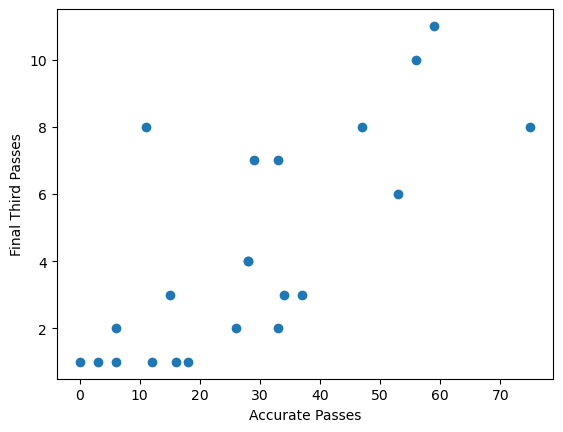

In [143]:
plt.xlabel('Accurate Passes')
plt.ylabel('Final Third Passes')

plt.plot(x_val, y_val, 'o')


In [111]:
spurs_bre_players = players[(players["team_code"] == 94) | (players["team_code"] == 6)].reset_index(drop=True)

In [118]:
spurs_bre["name"] = spurs_bre["player_id"].map(
    spurs_bre_players.set_index("player_id")["web_name"]
)

<Figure size 2000x1000 with 0 Axes>

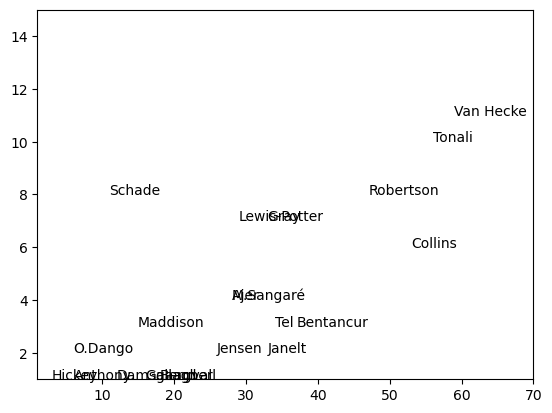

<Figure size 2000x1000 with 0 Axes>

In [152]:
for _, row in spurs_bre.iterrows():
    plt.annotate(row["name"], (row["accurate_passes"], row["final_third_passes"]))

plt.xlim(1, 70)
plt.ylim(1, 15)
plt.figure(figsize=(20, 10))

# 3. Force the axes to show a strict 70x10 grid layout